**Основна ідея**: складний сигнал можна представити як суму синусоїдальних і косинусоїдальних компонентів різних частот, амплітуд та фаз.

Дозволяє подивитись на зображення як на комбінацію просторових частот та дослідити як швидко змінюється яскравість зображення та в яких напрямках відбуваються ці зміни. Особливо корисно для:
* видалення періодичного шуму
* аналізу текстур і повторюваних структур
* придушення високих або низьких частот
* виявлення регулярних патернів
* аналізу розмиття та різклості
* частотної фільтрації зображень



In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from core.entities.constants import Paths as p

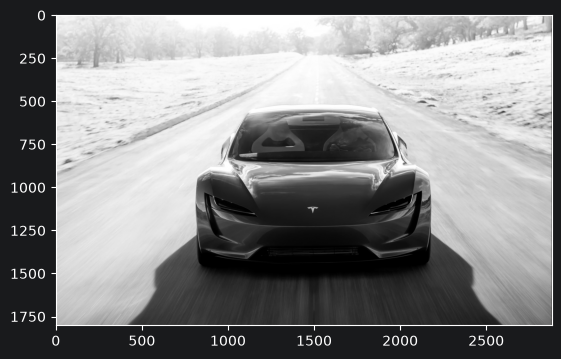

In [2]:
IMAGE_PATH = p.IMAGE_ASSETS / "tesla.png"

img = cv.imread(IMAGE_PATH, cv.IMREAD_GRAYSCALE)

plt.figure()
plt.imshow(img, cmap="gray" )

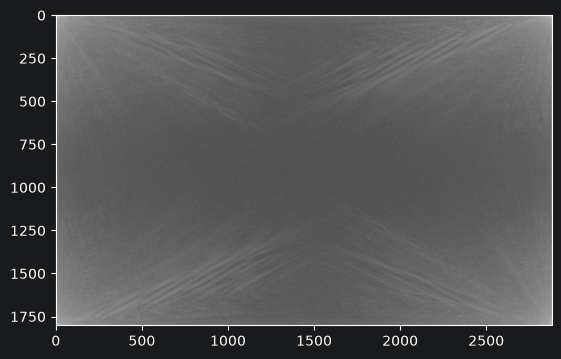

In [3]:
img_DFT = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
magnitude = cv.magnitude(img_DFT[:, :, 0], img_DFT[:, :, 1])
img_DFT_DB = 20 * np.log(magnitude)
plt.figure()
plt.imshow(img_DFT_DB, cmap="gray")


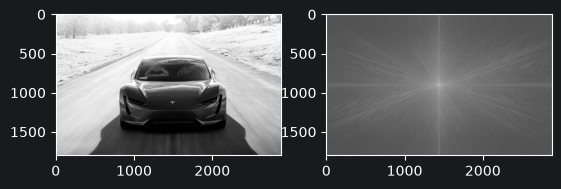

In [4]:
img_DFT_shift = np.fft.fftshift(img_DFT)
magnitude_shift = cv.magnitude(img_DFT_shift[:, :, 0], img_DFT_shift[:, :, 1])
img_DFT_shift_DB = 20 * np.log(magnitude_shift)
plt.figure()
plt.subplot(121)
plt.imshow(img, cmap="gray")
plt.subplot(122)
plt.imshow(img_DFT_shift_DB, cmap="gray")

Лінії спектру завжди направлені перпендикулярно напрямку лінії на зображенні

### apply low-pass filter

/tmp/ipykernel_18529/2021709190.py:13: RuntimeWarning: divide by zero encountered in log
  img_DFT_shift_LP_DB = 20 * np.log(magnitude_lp)


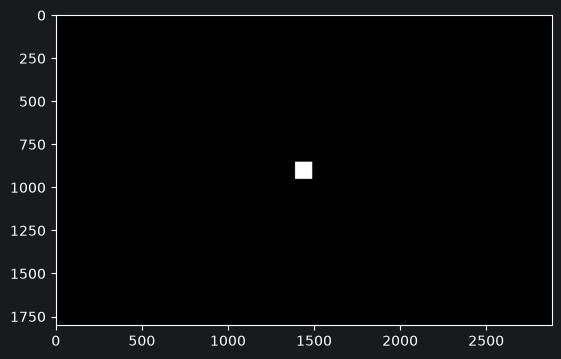

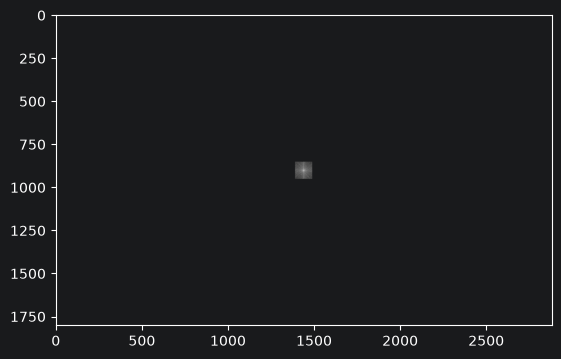

In [13]:
r, c = img.shape

mask = np.zeros((r, c, 2), np.uint8)

# take central area
offset = 50
mask[int(r / 2) - offset:int(r / 2) + offset, int(c / 2) - offset:int(c / 2) + offset] = 1
plt.figure()
plt.imshow(mask[:, :, 0], cmap="gray")

img_DFT_shift_LP = img_DFT_shift * mask
magnitude_lp = cv.magnitude(img_DFT_shift_LP[:, :, 0], img_DFT_shift_LP[:, :, 1])
img_DFT_shift_LP_DB = 20 * np.log(magnitude_lp)
plt.figure()
plt.imshow(img_DFT_shift_LP_DB, cmap="gray")


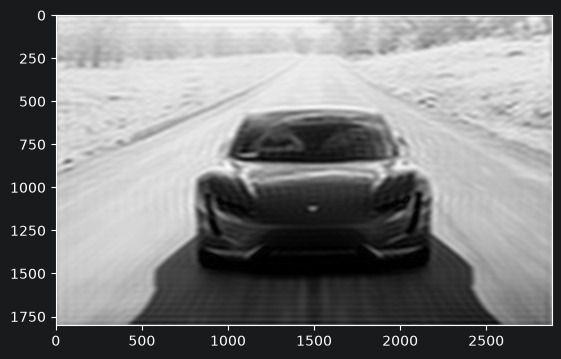

In [14]:
img_inv_DFT_LP = np.fft.ifftshift(img_DFT_shift_LP)
img_DFP_LP = cv.idft(img_inv_DFT_LP)

img_lp = cv.magnitude(img_DFP_LP[:, :, 0], img_DFP_LP[:, :, 1])

plt.figure()
plt.imshow(img_lp, cmap="gray")